# Mammalian Family Classification from COI-5P DNA Barcodes

**ISA 3 – AI Lab | Data Science and Data Engineering**  
**Students:** Prashant Naik (2607) and Karan Haldankar (2612)

## Project objective
Predict the **mammalian family** from a COI-5P DNA barcode sequence, then investigate individual false-positive and false-negative predictions.

### Important design decisions
- Keep **all family classes**, including families with very few records. Do not impose a minimum class-frequency cutoff.
- Use DNA-derived features as the primary model inputs. Do **not** use `genus`, `species`, `order`, `family`-related taxonomy, process IDs, or location as predictive features.
- Retain specimen/taxonomic metadata separately for later error investigation.
- Exact duplicate sequences must not be split between training and testing. Identical sequences with conflicting family labels are ambiguous and will be flagged and excluded from supervised modelling, while remaining in the audit table.
- A family represented by only one unique sequence cannot be evaluated on a held-out test set while also being present in training. Such families will remain in training and be explicitly reported as not independently testable.

This notebook is the first reproducible baseline. It reports the actual class distribution before modelling so rare-class limitations are visible.

> **Important:** This corrected version fixes sequence whitespace cleaning and the timing/evaluation cells. Because sequence cleaning can change the data, run the notebook from the beginning (`Kernel` → `Restart Kernel and Run All`) before using any metrics or exported CSV files.


## 1. Imports and configuration
Run this notebook from the folder containing the downloaded BOLD TSV, or update `DATA_PATH` below.

In [1]:
# If a package is missing, uncomment and run:
# %pip install pandas numpy scikit-learn matplotlib seaborn joblib

from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
TEST_SIZE = 0.20

# Change this if your TSV is stored elsewhere.
DATA_PATH = Path("DS-EBACMAMM.tsv")

# The BOLD export has many columns; load only those needed for the first phase.
REQUIRED_COLUMNS = [
    "processid", "sampleid", "family", "genus", "species",
    "nuc", "marker_code", "country/ocean", "province/state",
    "collection_date_start", "habitat", "identification",
]
print("Data file:", DATA_PATH.resolve())
print("File exists:", DATA_PATH.exists())


Data file: D:\MSC_AI\Fundamentals_Of_AI\Lab\mam_fam_class\DS-EBACMAMM.tsv
File exists: True


## 2. Load the BOLD dataset
The notebook checks the required fields and prints the dimensions. If the file is not found, update `DATA_PATH` to the location of the TSV.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Set DATA_PATH to the full path of your downloaded BOLD TSV."
    )

df = pd.read_csv(DATA_PATH, sep="\t", usecols=lambda c: c in REQUIRED_COLUMNS,
                 low_memory=False, dtype={"processid": "string"})
print("Rows:", len(df))
print("Columns loaded:", df.columns.tolist())
display(df.head(3))


Rows: 52263
Columns loaded: ['processid', 'sampleid', 'family', 'genus', 'species', 'identification', 'collection_date_start', 'country/ocean', 'province/state', 'habitat', 'nuc', 'marker_code']


,processid,sampleid,family,genus,species,identification,collection_date_start,country/ocean,province/state,habitat,nuc,marker_code
0,ABBID001-08,MZB M26934,Vespertilionidae,Kerivoula,Kerivoula krauensis,Kerivoula krauensis,NaN,Indonesia,Kalimantan Timur,NaN,ACCCTATATCTACTATTTGGTGCTTGAGCAGGCATAGTGGGAACCG...,COI-5P
1,ABBID032-09,B09_mw309,Erinaceidae,Echinosorex,Echinosorex gymnura,Echinosorex gymnura,2006-05-01,Indonesia,Kalimantan Tengah,NaN,AACTTATATATAATTTTTGGTGCTTGAGCCGGTATGGTAGGAACGT...,COI-5P
2,ABBID064-09,E05_wc41,Vespertilionidae,Kerivoula,Kerivoula krauensis,Kerivoula krauensis,NaN,Indonesia,Lampung,NaN,ACCCTATATCTACTATTTGGTGCTTGAGCAGGCATAGTGGGAACCG...,COI-5P


## 3. Select mammalian COI-5P records
We select rows where `marker_code` is exactly `COI-5P`, a family label is present, and a nucleotide sequence is available. **No family is removed based on its record count.**

In [3]:
df["marker_code"] = df["marker_code"].astype("string").str.strip()
df["family"] = df["family"].astype("string").str.strip()

coi = df[
    df["marker_code"].eq("COI-5P")
    & df["family"].notna()
    & df["family"].ne("")
    & df["nuc"].notna()
].copy()

print(f"Usable COI-5P records with family labels: {len(coi):,}")
print(f"Distinct family labels: {coi['family'].nunique():,}")
print(f"Distinct species labels (where supplied): {coi['species'].nunique(dropna=True):,}")


Usable COI-5P records with family labels: 39,678
Distinct family labels: 140
Distinct species labels (where supplied): 2,285


## 4. Clean and validate DNA sequences
For the first baseline, retain canonical DNA bases (`A`, `C`, `G`, `T`) and remove whitespace/gaps. Ambiguous bases are counted and flagged; records containing non-ACGT symbols are not used in the initial k-mer model, but are retained in the audit dataframe. This avoids silently treating ambiguous characters as ordinary nucleotides.

In [4]:
def clean_sequence(value):
    if pd.isna(value):
        return ""
    # Uppercase and remove all whitespace (spaces, tabs and line breaks).
    seq = re.sub(r"\s+", "", str(value).upper())
    # Remove alignment gap characters.
    seq = seq.replace("-", "").replace(".", "")
    return seq

coi["sequence_raw"] = coi["nuc"].astype("string")
coi["sequence"] = coi["sequence_raw"].map(clean_sequence)
coi["sequence_length"] = coi["sequence"].str.len()
coi["ambiguous_base_count"] = coi["sequence"].str.count(r"[^ACGT]")
coi["is_acgt_only"] = coi["sequence"].str.fullmatch(r"[ACGT]+").fillna(False)

print("Records with only A/C/G/T:", int(coi["is_acgt_only"].sum()))
print("Records containing ambiguous/non-ACGT symbols:", int((~coi["is_acgt_only"]).sum()))
print("Sequence length summary:")
display(coi["sequence_length"].describe())

# This audit table keeps excluded rows and the reason they were not modelled.
coi["audit_status"] = np.where(coi["is_acgt_only"], "eligible_for_baseline", "ambiguous_or_invalid_sequence")
display(coi[["processid", "family", "marker_code", "sequence_length",
             "ambiguous_base_count", "audit_status"]].head())


Records with only A/C/G/T: 34707
Records containing ambiguous/non-ACGT symbols: 4971
Sequence length summary:


count    39678.000000
mean       725.732648
std        242.058081
min        164.000000
25%        657.000000
50%        657.000000
75%        657.000000
max       1566.000000
Name: sequence_length, dtype: float64

,processid,family,marker_code,sequence_length,ambiguous_base_count,audit_status
0,ABBID001-08,Vespertilionidae,COI-5P,657,0,eligible_for_baseline
1,ABBID032-09,Erinaceidae,COI-5P,657,0,eligible_for_baseline
2,ABBID064-09,Vespertilionidae,COI-5P,657,0,eligible_for_baseline
3,ABBID079-09,Tupaiidae,COI-5P,648,0,eligible_for_baseline
4,ABBM002-05,Vespertilionidae,COI-5P,657,1,ambiguous_or_invalid_sequence


## 5. Inspect all family classes
This is an important decision point. We keep every family, including singleton and very rare families. The plot uses a logarithmic scale so that small classes remain visible beside very large ones.

Number of represented families: 140
Families with 1 record: 14
Families with fewer than 5 records: 38
Families with fewer than 10 records: 57


,family,record_count
0,Phyllostomidae,7456
1,Cricetidae,4388
2,Vespertilionidae,3951
3,Muridae,2847
4,Soricidae,1672
...,...,...
135,Thylacomyidae,1
136,Notoryctidae,1
137,Eupleridae,1
138,Mystacinidae,1


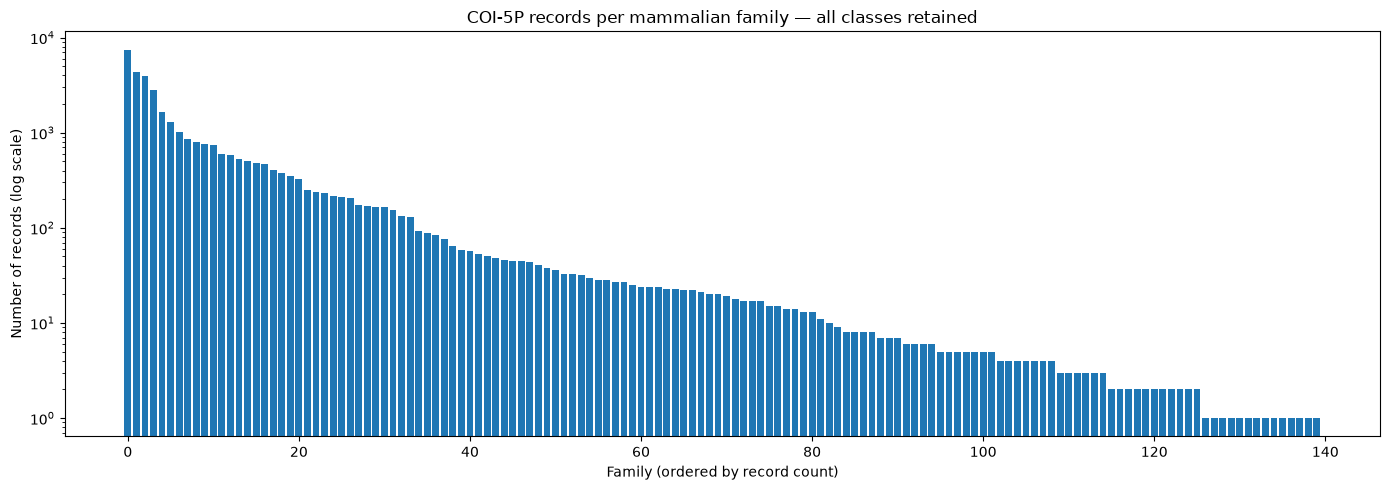

In [5]:
family_counts_all = (
    coi.loc[coi["is_acgt_only"], "family"]
    .value_counts()
    .rename_axis("family")
    .reset_index(name="record_count")
)

print("Number of represented families:", len(family_counts_all))
print("Families with 1 record:", int((family_counts_all.record_count == 1).sum()))
print("Families with fewer than 5 records:", int((family_counts_all.record_count < 5).sum()))
print("Families with fewer than 10 records:", int((family_counts_all.record_count < 10).sum()))
display(family_counts_all)

plt.figure(figsize=(14, 5))
plt.bar(np.arange(len(family_counts_all)), family_counts_all["record_count"])
plt.yscale("log")
plt.xlabel("Family (ordered by record count)")
plt.ylabel("Number of records (log scale)")
plt.title("COI-5P records per mammalian family — all classes retained")
plt.tight_layout()
plt.show()


## 6. Check exact duplicate sequences and conflicting labels
Repeated records with the same sequence and same family can inflate performance if copies enter both splits. We therefore model one row per unique sequence. If an identical sequence has more than one family label, its label is ambiguous; we exclude that sequence from supervised training/testing but keep all source records in `coi` for investigation.

In [6]:
eligible = coi.loc[coi["is_acgt_only"]].copy()
eligible["sequence"] = eligible["sequence"].astype(str)

seq_family_counts = eligible.groupby("sequence")["family"].nunique()
conflicting_sequences = set(seq_family_counts[seq_family_counts > 1].index)

print("Eligible source records:", len(eligible))
print("Unique sequences:", eligible["sequence"].nunique())
print("Repeated source records beyond first copy:",
      len(eligible) - eligible["sequence"].nunique())
print("Unique sequences associated with conflicting family labels:",
      len(conflicting_sequences))

# Keep one representative per unique sequence only when its family label is unambiguous.
unambiguous = eligible.loc[~eligible["sequence"].isin(conflicting_sequences)].copy()
model_df = (
    unambiguous.sort_values("processid", na_position="last")
    .drop_duplicates(subset=["sequence"], keep="first")
    .reset_index(drop=True)
)

print("Unique, unambiguous sequences for baseline modelling:", len(model_df))
print("Families remaining in model table:", model_df["family"].nunique())
print("Families represented in eligible records but absent after conflict filtering:",
      sorted(set(eligible["family"]) - set(model_df["family"])))


Eligible source records: 34707
Unique sequences: 17313
Repeated source records beyond first copy: 17394
Unique sequences associated with conflicting family labels: 4
Unique, unambiguous sequences for baseline modelling: 17309
Families remaining in model table: 140
Families represented in eligible records but absent after conflict filtering: []


## 7. Define the three validation strategies

We retain consistent duplicate records in the modelling table so that the grouped experiments are meaningful. Exact DNA sequences associated with conflicting family labels are excluded from supervised modelling, but remain available in the earlier audit table.

- **Validation A — Random split:** randomly divides individual records within each family. Identical sequences may land in both partitions. This is the least restrictive baseline.
- **Validation B.1 — Duplicate-grouped split:** all records with the same exact DNA sequence stay in one partition.
- **Validation B.2 — Species-grouped split:** all records with the same family + species stay together. It also keeps identical sequences together, even if their species labels differ. Missing species values are treated as record-specific groups, while exact-sequence grouping is still enforced.

Each strategy independently trains the same five classifiers: 3 strategies × 5 models = **15 model runs**.

In [7]:
# Prepare modelling records. Keep consistent duplicate records; exclude conflicting sequence labels.
eligible = coi.loc[coi["is_acgt_only"]].copy().reset_index(drop=True)
eligible["sequence"] = eligible["sequence"].astype(str)
eligible["_row_id"] = np.arange(len(eligible))

seq_family_counts = eligible.groupby("sequence")["family"].nunique()
conflicting_sequences = set(seq_family_counts[seq_family_counts > 1].index)

model_records = eligible.loc[
    ~eligible["sequence"].isin(conflicting_sequences)
].copy().reset_index(drop=True)

print("Eligible records:", len(eligible))
print("Unique exact sequences:", eligible["sequence"].nunique())
print("Repeated records beyond first copy:", len(eligible) - eligible["sequence"].nunique())
print("Conflicting sequences excluded:", len(conflicting_sequences))
print("Records retained for modelling (duplicates retained):", len(model_records))
print("Families retained:", model_records["family"].nunique())


Eligible records: 34707
Unique exact sequences: 17313
Repeated records beyond first copy: 17394
Conflicting sequences excluded: 4
Records retained for modelling (duplicates retained): 34688
Families retained: 140


## 8. Define the five classifiers

The same five model definitions and hyperparameters are used in every validation category.

In [8]:
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
import time

RANDOM_STATE = 42
TEST_SIZE = 0.20
KMER_SIZE = 4
OUTPUT_DIR = Path("family_classification_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

def make_models():
    return {
        "Multinomial Naive Bayes": MultinomialNB(alpha=0.5),
        "Logistic Regression": LogisticRegression(
            max_iter=500, class_weight="balanced",
            solver="saga", tol=1e-3, random_state=RANDOM_STATE
        ),
        "Linear SVM": LinearSVC(
            class_weight="balanced", random_state=RANDOM_STATE
        ),
        "Decision Tree": DecisionTreeClassifier(
            class_weight="balanced", random_state=RANDOM_STATE
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=200, class_weight="balanced",
            max_features="sqrt", min_samples_leaf=2,
            n_jobs=-1, random_state=RANDOM_STATE
        )
    }

print("Five models:", list(make_models()))


Five models: ['Multinomial Naive Bayes', 'Logistic Regression', 'Linear SVM', 'Decision Tree', 'Random Forest']


## 9. Create the three train/test splits

Splits are made separately within each family. Where a family has only one indivisible group, it remains in training and is listed as not independently testable. Grouped splits may differ from exactly 20% test data because groups cannot be divided.

In [9]:
def random_record_split(data, test_size=TEST_SIZE, random_state=RANDOM_STATE):
    rng = np.random.default_rng(random_state)
    train_ids, test_ids, not_testable = [], [], []
    for family, group in data.groupby("family", sort=True):
        ids = group.index.to_numpy(copy=True)
        rng.shuffle(ids)
        if len(ids) == 1:
            train_ids.extend(ids.tolist())
            not_testable.append(family)
            continue
        n_test = max(1, int(round(len(ids) * test_size)))
        n_test = min(n_test, len(ids) - 1)
        test_ids.extend(ids[:n_test].tolist())
        train_ids.extend(ids[n_test:].tolist())
    return (
        data.loc[train_ids].sample(frac=1, random_state=random_state).reset_index(drop=True),
        data.loc[test_ids].sample(frac=1, random_state=random_state).reset_index(drop=True),
        not_testable
    )


def grouped_split(data, group_col, test_size=TEST_SIZE, random_state=RANDOM_STATE):
    rng = np.random.default_rng(random_state)
    train_ids, test_ids, not_testable = [], [], []
    for family, group in data.groupby("family", sort=True):
        group_values = list(pd.unique(group[group_col]))
        rng.shuffle(group_values)
        if len(group_values) <= 1:
            train_ids.extend(group.index.tolist())
            not_testable.append(family)
            continue
        target = max(1, int(round(len(group) * test_size)))
        selected, selected_count = set(), 0
        for value in group_values[:-1]:
            selected.add(value)
            selected_count += int((group[group_col] == value).sum())
            if selected_count >= target:
                break
        for value in group_values:
            ids = group.index[group[group_col] == value].tolist()
            (test_ids if value in selected else train_ids).extend(ids)
    return (
        data.loc[train_ids].sample(frac=1, random_state=random_state).reset_index(drop=True),
        data.loc[test_ids].sample(frac=1, random_state=random_state).reset_index(drop=True),
        not_testable
    )


# A: ordinary random record split.
A_train, A_test, A_not_testable = random_record_split(model_records)

# B.1: identical sequence records are indivisible.
b1_data = model_records.copy()
b1_data["_duplicate_group"] = b1_data["sequence"]
B1_train, B1_test, B1_not_testable = grouped_split(b1_data, "_duplicate_group")

# B.2: connected groups join same family+species records and exact sequence records.
# Union-find ensures that neither species nor identical sequences cross partitions.
def species_duplicate_components(data):
    parent = list(range(len(data)))
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[rb] = ra

    first_species, first_sequence = {}, {}
    for pos, row in enumerate(data.itertuples()):
        sp = row.species
        if pd.notna(sp) and str(sp).strip():
            key = (str(row.family), str(sp).strip())
            if key in first_species:
                union(pos, first_species[key])
            else:
                first_species[key] = pos
        seq = row.sequence
        if seq in first_sequence:
            union(pos, first_sequence[seq])
        else:
            first_sequence[seq] = pos

    roots = [find(i) for i in range(len(data))]
    root_ids = {root: i for i, root in enumerate(dict.fromkeys(roots))}
    return [root_ids[root] for root in roots]

b2_data = model_records.copy()
b2_data["_species_duplicate_group"] = species_duplicate_components(b2_data)
B2_train, B2_test, B2_not_testable = grouped_split(
    b2_data, "_species_duplicate_group"
)

splits = {
    "Validation A - Random": (A_train, A_test, A_not_testable),
    "Validation B.1 - Duplicate Grouped": (B1_train, B1_test, B1_not_testable),
    "Validation B.2 - Species Grouped": (B2_train, B2_test, B2_not_testable)
}

split_summary_rows = []
for name, (tr, te, nt) in splits.items():
    split_summary_rows.append({
        "validation": name,
        "train_records": len(tr),
        "test_records": len(te),
        "train_families": tr["family"].nunique(),
        "test_families": te["family"].nunique(),
        "families_not_testable": len(nt),
        "actual_test_fraction": len(te) / (len(tr) + len(te))
    })
    print(f"{name}: train={len(tr):,}, test={len(te):,}, not-testable families={len(nt)}")

split_summary_df = pd.DataFrame(split_summary_rows)
display(split_summary_df)


Validation A - Random: train=27,741, test=6,947, not-testable families=14
Validation B.1 - Duplicate Grouped: train=27,552, test=7,136, not-testable families=14
Validation B.2 - Species Grouped: train=24,627, test=10,061, not-testable families=36


,validation,train_records,test_records,train_families,test_families,families_not_testable,actual_test_fraction
0,Validation A - Random,27741,6947,140,126,14,0.200271
1,Validation B.1 - Duplicate Grouped,27552,7136,140,126,14,0.205720
2,Validation B.2 - Species Grouped,24627,10061,140,104,36,0.290043


## 10. Verify leakage conditions

Validation A is intentionally permissive. B.1 must have zero exact-sequence overlap. B.2 must have zero exact-sequence and named family+species overlap.

In [10]:
def check_overlap(train, test, name):
    seq_overlap = set(train["sequence"]) & set(test["sequence"])
    train_species = {
        (str(r.family), str(r.species).strip())
        for r in train.itertuples()
        if pd.notna(r.species) and str(r.species).strip()
    }
    test_species = {
        (str(r.family), str(r.species).strip())
        for r in test.itertuples()
        if pd.notna(r.species) and str(r.species).strip()
    }
    species_overlap = train_species & test_species
    return {
        "validation": name,
        "exact_sequence_overlap": len(seq_overlap),
        "family_species_overlap": len(species_overlap)
    }

leakage_checks_df = pd.DataFrame([
    check_overlap(A_train, A_test, "Validation A - Random"),
    check_overlap(B1_train, B1_test, "Validation B.1 - Duplicate Grouped"),
    check_overlap(B2_train, B2_test, "Validation B.2 - Species Grouped")
])
display(leakage_checks_df)

assert leakage_checks_df.loc[1, "exact_sequence_overlap"] == 0
assert leakage_checks_df.loc[2, "exact_sequence_overlap"] == 0
assert leakage_checks_df.loc[2, "family_species_overlap"] == 0


,validation,exact_sequence_overlap,family_species_overlap
0,Validation A - Random,2151,1091
1,Validation B.1 - Duplicate Grouped,0,964
2,Validation B.2 - Species Grouped,0,0


## 11. Train five models in each validation category

A separate character k-mer vectorizer is fitted on each training partition only. The same five models are trained independently in all three categories. The Random Forest uses its own internal parallelism; the 15 experiments run sequentially to avoid nested parallel processing.

In [11]:
def run_experiment(validation_name, train_df, test_df):
    print("\\n" + "=" * 75)
    print(validation_name)
    print("=" * 75)

    vectorizer = CountVectorizer(
        analyzer="char",
        ngram_range=(KMER_SIZE, KMER_SIZE),
        lowercase=False,
        dtype=np.float32
    )
    X_train = vectorizer.fit_transform(train_df["sequence"])
    X_test = vectorizer.transform(test_df["sequence"])
    y_train = train_df["family"].to_numpy()
    y_test = test_df["family"].to_numpy()

    print("X_train:", X_train.shape, "| X_test:", X_test.shape)
    fitted, predictions, rows = {}, {}, []

    for model_name, model in make_models().items():
        print("Training:", model_name)
        start = time.perf_counter()
        model.fit(X_train, y_train)
        train_seconds = time.perf_counter() - start

        start = time.perf_counter()
        pred = model.predict(X_test)
        predict_seconds = time.perf_counter() - start

        precision, recall, f1, _ = precision_recall_fscore_support(
            y_test, pred, average="macro", zero_division=0
        )
        fitted[model_name] = model
        predictions[model_name] = pred
        rows.append({
            "validation": validation_name,
            "model": model_name,
            "accuracy": accuracy_score(y_test, pred),
            "macro_precision": precision,
            "macro_recall": recall,
            "macro_f1": f1,
            "training_time_sec": train_seconds,
            "prediction_time_sec": predict_seconds,
            "train_records": len(train_df),
            "test_records": len(test_df)
        })
        print(f"  macro-F1={f1:.4f}; train={train_seconds:.2f}s; predict={predict_seconds:.2f}s")

    return {
        "vectorizer": vectorizer,
        "models": fitted,
        "predictions": predictions,
        "metrics": pd.DataFrame(rows),
        "train_df": train_df.copy(),
        "test_df": test_df.copy()
    }


experiment_results = {}
for validation_name, (tr, te, _) in splits.items():
    experiment_results[validation_name] = run_experiment(validation_name, tr, te)

all_model_results = pd.concat(
    [result["metrics"] for result in experiment_results.values()],
    ignore_index=True
)
print("Total model runs:", len(all_model_results))
assert len(all_model_results) == 15
display(all_model_results.sort_values(["validation", "macro_f1"], ascending=[True, False]))


\n===========================================================================
Validation A - Random
X_train: (27741, 256) | X_test: (6947, 256)
Training: Multinomial Naive Bayes
  macro-F1=0.7712; train=0.27s; predict=0.05s
Training: Logistic Regression


: 

: 

## 12. Compare the 15 model runs

In [ ]:
macro_f1_comparison = all_model_results.pivot(
    index="model", columns="validation", values="macro_f1"
)
accuracy_comparison = all_model_results.pivot(
    index="model", columns="validation", values="accuracy"
)
display(macro_f1_comparison)
display(accuracy_comparison)

ax = macro_f1_comparison.plot(kind="bar", figsize=(14, 6))
ax.set_ylabel("Macro-F1")
ax.set_title("Five classifiers across three validation strategies")
ax.set_ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


## 13. Classification reports for all 15 runs

In [ ]:
for validation_name, result in experiment_results.items():
    print("\\n" + "#" * 75)
    print(validation_name)
    for model_name, pred in result["predictions"].items():
        print(f"\\n--- {model_name} ---")
        print(classification_report(
            result["test_df"]["family"],
            pred,
            labels=sorted(result["test_df"]["family"].unique()),
            zero_division=0
        ))


## 14. Record-level predictions and error analysis tables

In [ ]:
prediction_tables = {}
metadata_columns = [
    c for c in [
        "processid", "sampleid", "family", "genus", "species",
        "country/ocean", "province/state", "collection_date_start",
        "habitat", "sequence", "sequence_length", "ambiguous_base_count"
    ] if c in model_records.columns
]

for (validation_name, _), result in [
    (key, value)
    for key, value in experiment_results.items()
]:
    test_df = result["test_df"].reset_index(drop=True)
    for model_name, pred in result["predictions"].items():
        table = test_df[metadata_columns].copy().rename(columns={"family": "actual_family"})
        table["validation"] = validation_name
        table["model"] = model_name
        table["predicted_family"] = pred
        table["correct"] = table["actual_family"].eq(table["predicted_family"])
        table["error_type"] = np.where(table["correct"], "correct", "misclassified")
        prediction_tables[(validation_name, model_name)] = table

all_predictions = pd.concat(prediction_tables.values(), ignore_index=True)
all_misclassifications = all_predictions.loc[~all_predictions["correct"]].copy()
print("Prediction rows across all runs:", len(all_predictions))
print("Misclassified prediction rows:", len(all_misclassifications))
display(all_misclassifications.head(10))


## 15. Per-family one-vs-rest TP, TN, FP and FN

In [ ]:
confusion_rows = []
for (validation_name, model_name), table in prediction_tables.items():
    y_true = table["actual_family"].to_numpy()
    y_pred = table["predicted_family"].to_numpy()
    for family in sorted(set(y_true) | set(y_pred)):
        actual_positive = y_true == family
        predicted_positive = y_pred == family
        confusion_rows.append({
            "validation": validation_name,
            "model": model_name,
            "family": family,
            "TP": int(np.sum(actual_positive & predicted_positive)),
            "TN": int(np.sum(~actual_positive & ~predicted_positive)),
            "FP": int(np.sum(~actual_positive & predicted_positive)),
            "FN": int(np.sum(actual_positive & ~predicted_positive))
        })

per_family_confusion = pd.DataFrame(confusion_rows)
display(per_family_confusion.sort_values(["FN", "FP"], ascending=False).head(30))


## 16. Export results

In [ ]:
family_counts_all.to_csv(OUTPUT_DIR / "family_record_counts.csv", index=False)
split_summary_df.to_csv(OUTPUT_DIR / "validation_split_summary.csv", index=False)
leakage_checks_df.to_csv(OUTPUT_DIR / "validation_leakage_checks.csv", index=False)
all_model_results.to_csv(OUTPUT_DIR / "all_15_model_results.csv", index=False)
macro_f1_comparison.to_csv(OUTPUT_DIR / "macro_f1_comparison.csv")
accuracy_comparison.to_csv(OUTPUT_DIR / "accuracy_comparison.csv")

all_predictions.drop(columns=["sequence"], errors="ignore").to_csv(
    OUTPUT_DIR / "all_model_predictions.csv", index=False
)
all_misclassifications.drop(columns=["sequence"], errors="ignore").to_csv(
    OUTPUT_DIR / "all_model_misclassifications.csv", index=False
)
per_family_confusion.to_csv(
    OUTPUT_DIR / "per_family_TP_TN_FP_FN_all_experiments.csv", index=False
)

coi[[
    c for c in ["processid", "family", "marker_code", "sequence_length",
                "ambiguous_base_count", "audit_status"] if c in coi.columns
]].to_csv(OUTPUT_DIR / "record_quality_audit.csv", index=False)

eligible.loc[eligible["sequence"].isin(conflicting_sequences)].to_csv(
    OUTPUT_DIR / "conflicting_sequence_family_labels.csv", index=False
)

print("Saved outputs to:", OUTPUT_DIR.resolve())
for p in sorted(OUTPUT_DIR.iterdir()):
    print(p.name, "-", f"{p.stat().st_size:,} bytes")


## 17. Interpretation and limitations

### What the three categories measure
- **Validation A:** performance on randomly held-out records; exact duplicates and other records from the same species may be present in training.
- **Validation B.1:** performance when exact identical DNA sequences are never shared between training and testing.
- **Validation B.2:** performance on held-out species, while also preventing exact identical sequences from crossing partitions.

### Important cautions
1. A family with only one indivisible group cannot be tested while also remaining in training. It is retained in training and reported as not independently testable.
2. Grouped splits can have a test fraction different from 20%, because groups cannot be divided.
3. B.2 groups records together when they share either the same family+species label or the same exact sequence. This can merge multiple species if the same sequence is annotated under different species names.
4. Missing species labels are treated as record-specific groups; identical sequences are still kept together.
5. Validation A is intentionally permissive and may be optimistic if duplicates or near-related records cross partitions.
6. Model metrics are reported on each category's test partition. Do not choose a final model using these test scores and then claim the same score as an unbiased final estimate. A later stage should add validation data or grouped cross-validation for model selection.
7. Only DNA k-mer features are predictive inputs. Taxonomic/specimen metadata is used only for grouping, auditing and error analysis.
8. The current experiments use A/C/G/T-only sequences. Ambiguous nucleotide handling, alternative k-mer sizes, TF-IDF, hyperparameter tuning and biological alignment can be separate future experiments.

### Recommended next steps
1. Run the entire notebook from the beginning.
2. Check `validation_split_summary.csv` and `validation_leakage_checks.csv` first.
3. Compare macro-F1 across all three categories.
4. Inspect misclassified records and family-level FP/FN counts.
5. Then proceed to model-selection design and sequence-similarity analysis.
